# Batch Normalization from Scratch (PyTorch)

Following [D2L §8.5 Batch Normalization](https://d2l.ai/chapter_convolutional-modern/batch-norm.html) and [Ioffe & Szegedy, 2015](https://arxiv.org/abs/1502.03167).

Batch normalization (BN) re-centres and re-scales each layer's inputs using statistics of the current minibatch. In practice it lets deep networks train **faster**, with **larger learning rates**, and less sensitivity to initialization.

**Contents**
1. The BN computation, by hand
2. A `BatchNorm` layer (fully connected and convolutional)
3. LeNet with vs. without BN on Fashion-MNIST
4. The concise version with `nn.BatchNorm2d`

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lee2716/Dive_into_Deep_Learning_Code_Implementation/blob/main/batch_norm.ipynb)

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


## 1. The Computation

For a minibatch $\mathcal{B}$, BN normalizes each feature and then applies a learnable scale $\boldsymbol{\gamma}$ and shift $\boldsymbol{\beta}$:

$$\hat{\boldsymbol{\mu}}_\mathcal{B} = \frac{1}{|\mathcal{B}|}\sum_{\mathbf{x} \in \mathcal{B}} \mathbf{x}, \qquad
\hat{\boldsymbol{\sigma}}^2_\mathcal{B} = \frac{1}{|\mathcal{B}|}\sum_{\mathbf{x} \in \mathcal{B}} (\mathbf{x} - \hat{\boldsymbol{\mu}}_\mathcal{B})^2 + \epsilon$$

$$\mathrm{BN}(\mathbf{x}) = \boldsymbol{\gamma} \odot \frac{\mathbf{x} - \hat{\boldsymbol{\mu}}_\mathcal{B}}{\hat{\boldsymbol{\sigma}}_\mathcal{B}} + \boldsymbol{\beta}$$

Details that matter:
- **Fully connected layers:** statistics per feature, over the batch (dim 0).
- **Conv layers:** statistics per *channel*, over batch, height and width (dims 0, 2, 3).
- **Training vs. prediction:** during training we use the minibatch statistics and keep a running (moving) average of them; at prediction time we use the moving averages, so the output for one example doesn't depend on the rest of the batch.

In [2]:
def batch_norm(X, gamma, beta, moving_mean, moving_var, eps, momentum):
    if not torch.is_grad_enabled():
        # prediction mode: use the moving averages
        X_hat = (X - moving_mean) / torch.sqrt(moving_var + eps)
    else:
        assert len(X.shape) in (2, 4)
        if len(X.shape) == 2:      # fully connected: per feature
            mean = X.mean(dim=0)
            var = ((X - mean) ** 2).mean(dim=0)
        else:                      # convolution: per channel
            mean = X.mean(dim=(0, 2, 3), keepdim=True)
            var = ((X - mean) ** 2).mean(dim=(0, 2, 3), keepdim=True)
        X_hat = (X - mean) / torch.sqrt(var + eps)
        moving_mean = (1.0 - momentum) * moving_mean + momentum * mean
        moving_var = (1.0 - momentum) * moving_var + momentum * var
    Y = gamma * X_hat + beta
    return Y, moving_mean.data, moving_var.data

Check: after BN (with $\gamma = 1, \beta = 0$) every channel has mean ≈ 0 and variance ≈ 1, whatever the input scale.

In [3]:
X = torch.randn(16, 3, 8, 8) * 5 + 10            # mean 10, std 5
shape = (1, 3, 1, 1)
Y, _, _ = batch_norm(X, torch.ones(shape), torch.zeros(shape),
                     torch.zeros(shape), torch.ones(shape), eps=1e-5, momentum=0.1)
print('input  mean/var per channel:', X.mean(dim=(0, 2, 3)), X.var(dim=(0, 2, 3), unbiased=False))
print('output mean/var per channel:', Y.mean(dim=(0, 2, 3)), Y.var(dim=(0, 2, 3), unbiased=False))

input  mean/var per channel: tensor([10.1123,  9.8262, 10.0351]) tensor([26.4811, 24.5489, 24.2755])
output mean/var per channel: tensor([2.0210e-07, 4.8894e-08, 1.0896e-07]) tensor([1.0000, 1.0000, 1.0000])


## 2. A `BatchNorm` Layer

The layer owns the learnable parameters (`gamma`, `beta`) and the non-learnable moving statistics. We switch to prediction mode with `torch.no_grad()` inside evaluation, which the `batch_norm` function detects.

In [4]:
class BatchNorm(nn.Module):
    def __init__(self, num_features, num_dims):
        super().__init__()
        shape = (1, num_features) if num_dims == 2 else (1, num_features, 1, 1)
        self.gamma = nn.Parameter(torch.ones(shape))
        self.beta = nn.Parameter(torch.zeros(shape))
        # buffers move with .to(device) and are saved in state_dict, but get no gradients
        self.register_buffer('moving_mean', torch.zeros(shape))
        self.register_buffer('moving_var', torch.ones(shape))

    def forward(self, X):
        Y, self.moving_mean, self.moving_var = batch_norm(
            X, self.gamma, self.beta, self.moving_mean, self.moving_var,
            eps=1e-5, momentum=0.1)
        return Y

## 3. LeNet With and Without BN

BN goes **after** the conv / linear layer and **before** the activation.

In [5]:
def lenet(use_bn):
    def bn(n, dims):
        return [BatchNorm(n, num_dims=dims)] if use_bn else []
    return nn.Sequential(
        nn.Conv2d(1, 6, kernel_size=5, padding=2), *bn(6, 4), nn.Sigmoid(),
        nn.AvgPool2d(kernel_size=2, stride=2),
        nn.Conv2d(6, 16, kernel_size=5), *bn(16, 4), nn.Sigmoid(),
        nn.AvgPool2d(kernel_size=2, stride=2), nn.Flatten(),
        nn.Linear(16 * 5 * 5, 120), *bn(120, 2), nn.Sigmoid(),
        nn.Linear(120, 84), *bn(84, 2), nn.Sigmoid(),
        nn.Linear(84, 10))

In [6]:
trans = transforms.ToTensor()
train_set = datasets.FashionMNIST(root='./data', train=True, transform=trans, download=True)
test_set = datasets.FashionMNIST(root='./data', train=False, transform=trans, download=True)
train_iter = DataLoader(train_set, batch_size=256, shuffle=True, num_workers=2)
test_iter = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)


def evaluate_accuracy(net, data_iter):
    net.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X, y in data_iter:
            X, y = X.to(device), y.to(device)
            correct += (net(X).argmax(dim=1) == y).sum().item()
            total += y.numel()
    return correct / total


def train(net, num_epochs, lr):
    net.to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'test_acc': []}
    for epoch in range(num_epochs):
        net.train()
        loss_sum, total = 0.0, 0
        for X, y in train_iter:
            X, y = X.to(device), y.to(device)
            loss = loss_fn(net(X), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * y.numel()
            total += y.numel()
        history['train_loss'].append(loss_sum / total)
        history['test_acc'].append(evaluate_accuracy(net, test_iter))
        print(f"epoch {epoch + 1:2d}: loss {history['train_loss'][-1]:.3f}, test acc {history['test_acc'][-1]:.3f}")
    return history

Same learning rate and number of epochs for both.

**Result:** the sigmoid LeNet *without* BN doesn't learn at all in 5 epochs at this setting (loss stays at ln 10 ≈ 2.30, i.e. random guessing), while the BN version reaches ~84% test accuracy. Normalizing the inputs of each sigmoid keeps it in its non-saturated range, so gradients can flow.

In [7]:
num_epochs, lr = 5, 0.5
print('--- LeNet without BN ---')
hist_plain = train(lenet(use_bn=False), num_epochs, lr)
print('--- LeNet with BN ---')
net_bn = lenet(use_bn=True)
hist_bn = train(net_bn, num_epochs, lr)

--- LeNet without BN ---


epoch  1: loss 2.315, test acc 0.100


epoch  2: loss 2.308, test acc 0.100


epoch  3: loss 2.305, test acc 0.100


epoch  4: loss 2.305, test acc 0.100


...

epoch  1: loss 0.696, test acc 0.791


epoch  2: loss 0.440, test acc 0.831


epoch  3: loss 0.378, test acc 0.846


epoch  4: loss 0.343, test acc 0.839


epoch  5: loss 0.318, test acc 0.839


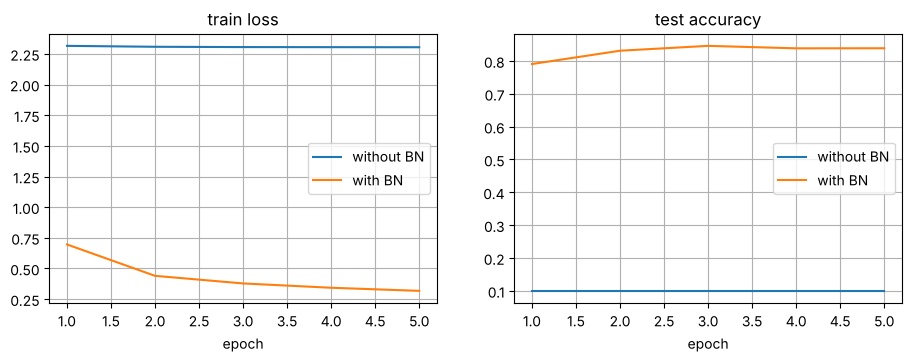

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
epochs = range(1, num_epochs + 1)
ax1.plot(epochs, hist_plain['train_loss'], label='without BN')
ax1.plot(epochs, hist_bn['train_loss'], label='with BN')
ax1.set_title('train loss'); ax1.set_xlabel('epoch'); ax1.legend(); ax1.grid(True)
ax2.plot(epochs, hist_plain['test_acc'], label='without BN')
ax2.plot(epochs, hist_bn['test_acc'], label='with BN')
ax2.set_title('test accuracy'); ax2.set_xlabel('epoch'); ax2.legend(); ax2.grid(True)
plt.show()

The learned scale and shift of the first BN layer:

In [9]:
print('gamma:', net_bn[1].gamma.reshape(-1).data)
print('beta: ', net_bn[1].beta.reshape(-1).data)

gamma: tensor([2.2032, 1.7638, 1.6108, 2.5117, 2.0618, 2.0796])
beta:  tensor([-1.6200, -0.7044, -0.7997,  1.3706, -0.0079, -0.7721])


## 4. Concise Implementation

`nn.BatchNorm2d` / `nn.BatchNorm1d` do the same thing (in optimized C++/CUDA) and switch modes via `net.train()` / `net.eval()`. Note they don't need `num_dims`, and PyTorch's `momentum=0.1` has the same meaning as ours.

In [10]:
net = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.BatchNorm2d(6), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Conv2d(6, 16, kernel_size=5), nn.BatchNorm2d(16), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2), nn.Flatten(),
    nn.Linear(400, 120), nn.BatchNorm1d(120), nn.Sigmoid(),
    nn.Linear(120, 84), nn.BatchNorm1d(84), nn.Sigmoid(),
    nn.Linear(84, 10))
hist_builtin = train(net, num_epochs, lr)

epoch  1: loss 0.706, test acc 0.799


epoch  2: loss 0.446, test acc 0.812


epoch  3: loss 0.377, test acc 0.533


epoch  4: loss 0.341, test acc 0.837


epoch  5: loss 0.313, test acc 0.722


Test accuracy can jump around from epoch to epoch at this large learning rate: evaluation uses the moving averages, which lag behind the quickly changing weights. A smaller `lr` or more epochs smooths this out.

## Exercises

1. Remove the bias from the conv / linear layers that come right before BN. Why is it redundant?
2. Try `lr = 2.0` with and without BN. Which one still trains?
3. Evaluate `net_bn` with `torch.enable_grad()` around the test loop (so it wrongly uses batch statistics) and batch size 1. What happens to accuracy, and why?